# 🎯 Smart Outcome Predictor — Ensemble-Based ML System

**Role:** Machine Learning Engineer at an EdTech analytics company  
**Tasks:** (1) *Classification* → will a student **complete** the course? (2) *Regression* → predict the student's **final performance score**  
**Methods:** Bagging · AdaBoost · XGBoost · Voting (hard & soft) · Stacking  

**Notebook map**

| Part | Content |
|---|---|
| A | Conceptual foundation (theory, Q1-5) |
| B | Dataset understanding, EDA & preprocessing (Q6-8) |
| C | Bagging (Q9-11) |
| D | Boosting – AdaBoost & XGBoost (Q12-17) |
| E | Voting & Stacking (Q18-21) |
| F | Model evaluation & comparison (Q22-30) |
| G | Final analysis, report & recommendation (Q31-32) |

---
# 🧠 Part A: Conceptual Foundation (Theory)

### Q1. What are Ensemble Learning Methods and why are they effective?
Ensemble learning combines the predictions of several models (*base learners*) into one final prediction.
It works because the errors of different models are only partly correlated: averaging or voting cancels out random mistakes
(**lower variance**), sequential correction removes systematic mistakes (**lower bias**), and diverse models cover each other's blind spots.
The result is usually higher accuracy, better generalisation and more stable results than any single model.

### Q2. Difference between Bagging, Boosting and Voting

| | **Bagging** | **Boosting** | **Voting** |
|---|---|---|---|
| Training | Parallel, each model on a *bootstrap sample* | Sequential, each model learns from the previous model's mistakes | Independent models trained on the *same* data |
| Base learners | Same algorithm (usually deep trees) | Same algorithm (weak learners: stumps/shallow trees) | *Different* algorithms (LR, SVM, RF…) |
| Combination | Average / majority vote | Weighted sum | Majority (hard) or mean probability (soft) |
| Main effect | Reduces **variance** | Reduces **bias** | Balances different strengths |
| Examples | Bagging, Random Forest | AdaBoost, Gradient Boosting, XGBoost | VotingClassifier / VotingRegressor |

### Q3. Bias–Variance trade-off and how ensembles address it
Expected error = **Bias² + Variance + Noise**. Simple models have high bias (under-fit); very flexible models have high variance (over-fit);
lowering one usually raises the other. **Bagging** averages many high-variance, low-bias trees, which cuts variance without raising bias.
**Boosting** adds weak (high-bias) learners one after another so the bias keeps shrinking, while learning-rate shrinkage and subsampling keep variance in check.
**Voting/Stacking** mix diverse models so their individual biases and variances partly cancel.

### Q4. Voting Classifier and Stacking Ensemble
**Voting Classifier:** several different classifiers predict independently. *Hard voting* picks the class with the most votes; *soft voting* averages the predicted
probabilities (optionally weighted) and picks the highest – it uses the confidence of each model, so it is usually better when models are calibrated.  
**Stacking:** the base learners' **out-of-fold predictions** become the input features of a **meta-learner** (e.g. Logistic Regression / Ridge) that *learns* how much to trust each base model.
Cross-validated predictions prevent the meta-learner from seeing leaked labels.

### Q5. AdaBoost vs XGBoost (conceptual)

| | **AdaBoost** | **XGBoost** |
|---|---|---|
| Idea | Re-weights *misclassified samples*; next weak learner focuses on them | Fits each new tree to the *gradient (and Hessian)* of a loss function |
| Learners | Stumps / shallow trees, combined with accuracy-based weights | Regularised CART trees with leaf weights |
| Loss | Exponential loss (classification) | Any differentiable loss (log-loss, squared error…) |
| Regularisation | Only learning rate / number of estimators | L1 + L2 penalties, `gamma`, shrinkage, row & column subsampling |
| Practical | Simple, but sensitive to noise and outliers | Faster (parallel split search), handles missing values, usually more accurate and robust |

---
# 🧪 Part B: Dataset Understanding & Preparation

In [1]:
import warnings, os, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor,
                              AdaBoostClassifier, AdaBoostRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor,
                              VotingClassifier, VotingRegressor,
                              StackingClassifier, StackingRegressor)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

# XGBoost (install with: pip install xgboost). If it is missing we fall back to sklearn's
# HistGradientBoosting, which is the same algorithm family (second-order gradient boosted trees).
try:
    from xgboost import XGBClassifier, XGBRegressor
    XGB_NATIVE = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
    XGB_NATIVE = False

RANDOM_STATE = 42
for d in ["plots", "outputs", "models"]:
    os.makedirs(d, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"plots/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Native XGBoost available:", XGB_NATIVE)

Native XGBoost available: False


In [2]:
# Load the dataset (looks in ./data first, then the current folder)
for p in ["data/Smart_Outcome_Predictor_Dataset_5200.csv", "Smart_Outcome_Predictor_Dataset_5200.csv"]:
    if os.path.exists(p):
        df = pd.read_csv(p); break
print("Shape:", df.shape)
df.head()

Shape: (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [3]:
display(df.dtypes.to_frame("dtype").T)
miss = df.isna().sum().to_frame("missing"); miss["missing_%"] = (miss["missing"] / len(df) * 100).round(2)
print("Missing values:"); display(miss[miss["missing"] > 0])
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate student_id:", df["student_id"].duplicated().sum())
df.describe().T.round(2)

Missing values:
Duplicate rows: 0 | Duplicate student_id: 0


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
dtype,int64,int64,str,str,str,str,str,str,int64,int64,float64,int64,int64,int64,int64,float64,float64,int64,float64


,missing,missing_%
time_spent_hours,112,2.15
avg_quiz_score,81,1.56
attendance_rate,80,1.54


,count,mean,std,min,25%,50%,75%,max
student_id,5200.0,702600.50,1501.26,700001.00,701300.75,702600.50,703900.25,705200.0
age,5200.0,24.34,5.58,16.00,20.00,24.00,28.00,45.0
week_of_year,5200.0,26.62,15.01,1.00,14.00,27.00,40.00,52.0
sessions,5200.0,19.12,10.73,1.00,11.00,17.00,25.00,94.0
time_spent_hours,5088.0,18.22,10.73,0.60,10.30,16.10,23.80,76.8
videos_watched,5200.0,25.85,17.72,0.00,13.00,23.00,35.00,158.0
quiz_attempts,5200.0,7.00,2.57,0.00,5.00,7.00,9.00,20.0
assignments_submitted,5200.0,3.84,1.95,0.00,2.00,4.00,5.00,12.0
forum_posts,5200.0,1.59,1.27,0.00,1.00,1.00,2.00,8.0
avg_quiz_score,5119.0,66.84,13.81,0.00,57.50,66.90,76.20,100.0


{0: 0.625, 1: 0.375}


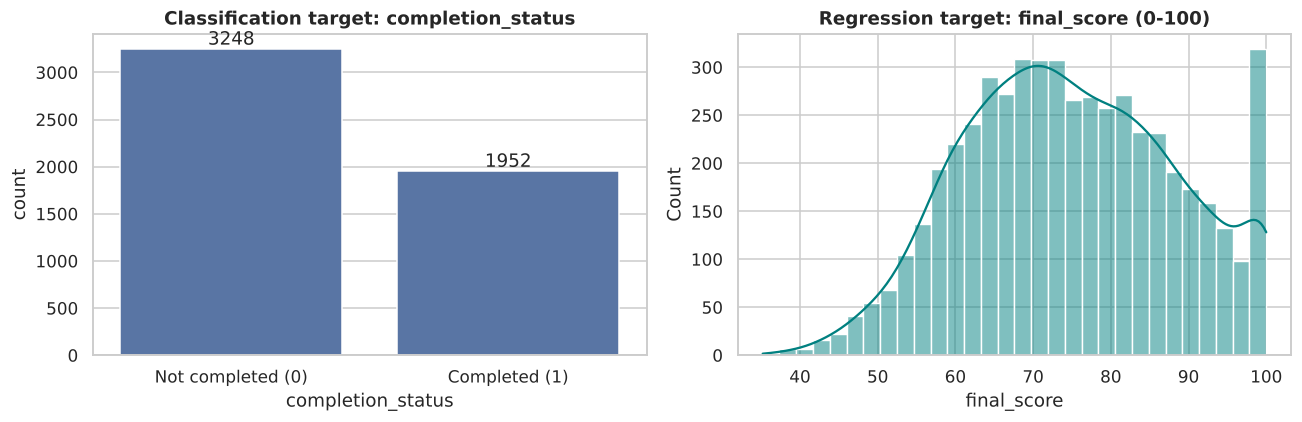

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="completion_status", data=df, ax=ax[0])
ax[0].set_title("Classification target: completion_status"); ax[0].set_xticklabels(["Not completed (0)", "Completed (1)"])
for c in ax[0].containers: ax[0].bar_label(c)
sns.histplot(df["final_score"], bins=30, kde=True, ax=ax[1], color="teal")
ax[1].set_title("Regression target: final_score (0-100)")
savefig("01_target_distribution")
print(df["completion_status"].value_counts(normalize=True).round(3).to_dict())


**Interpretation.** About **37.5 % of students complete** the course (62.5 % do not) — a mild class imbalance, which is why the classification split is stratified and why we judge models with **F1 and ROC-AUC**, not accuracy alone.
`final_score` is bounded at 100 with a mean of about 75, so a model that always predicted the mean would already be "close" — R² and RMSE (not just MAE) tell us how much better than that baseline a model really is.


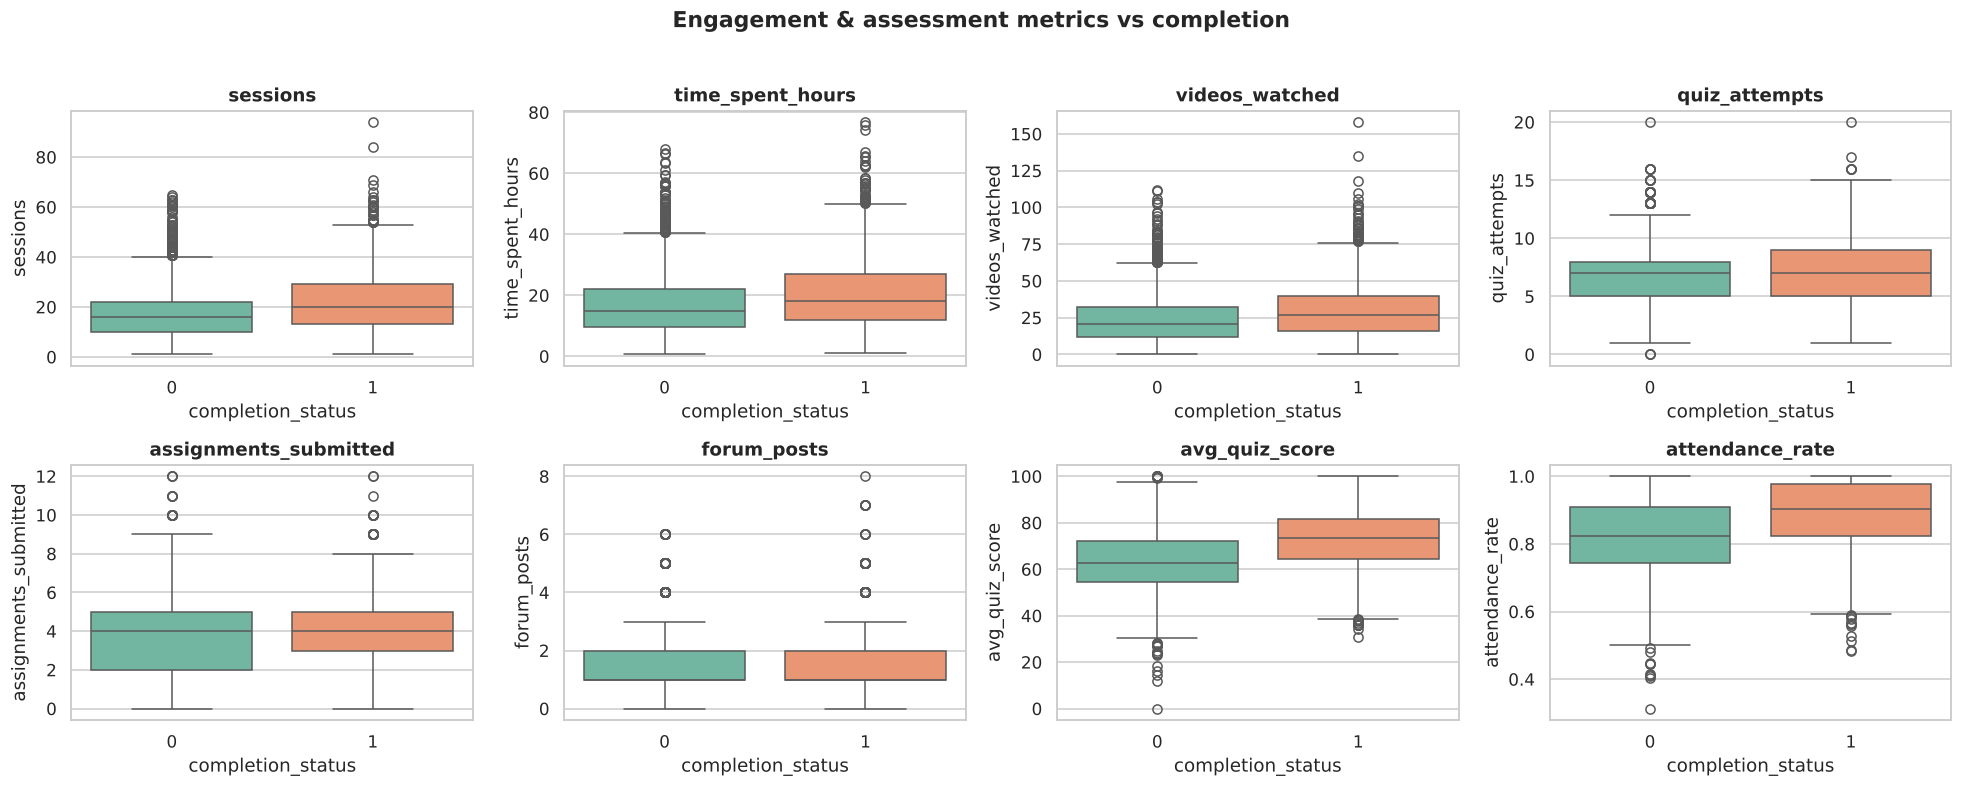

In [5]:
num_eda = ["sessions", "time_spent_hours", "videos_watched", "quiz_attempts", "assignments_submitted",
           "forum_posts", "avg_quiz_score", "attendance_rate"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for a, c in zip(axes.ravel(), num_eda):
    sns.boxplot(x="completion_status", y=c, data=df, ax=a, palette="Set2"); a.set_title(c)
plt.suptitle("Engagement & assessment metrics vs completion", y=1.02, fontweight="bold")
savefig("02_features_vs_completion")

,completion_status,final_score
avg_quiz_score,0.34,0.52
attendance_rate,0.27,0.31
time_spent_hours,0.16,0.30
videos_watched,0.17,0.26
sessions,0.21,0.25
assignments_submitted,0.05,0.23
quiz_attempts,0.05,0.06
forum_posts,0.01,0.06
week_of_year,0.00,0.00
age,-0.00,-0.01


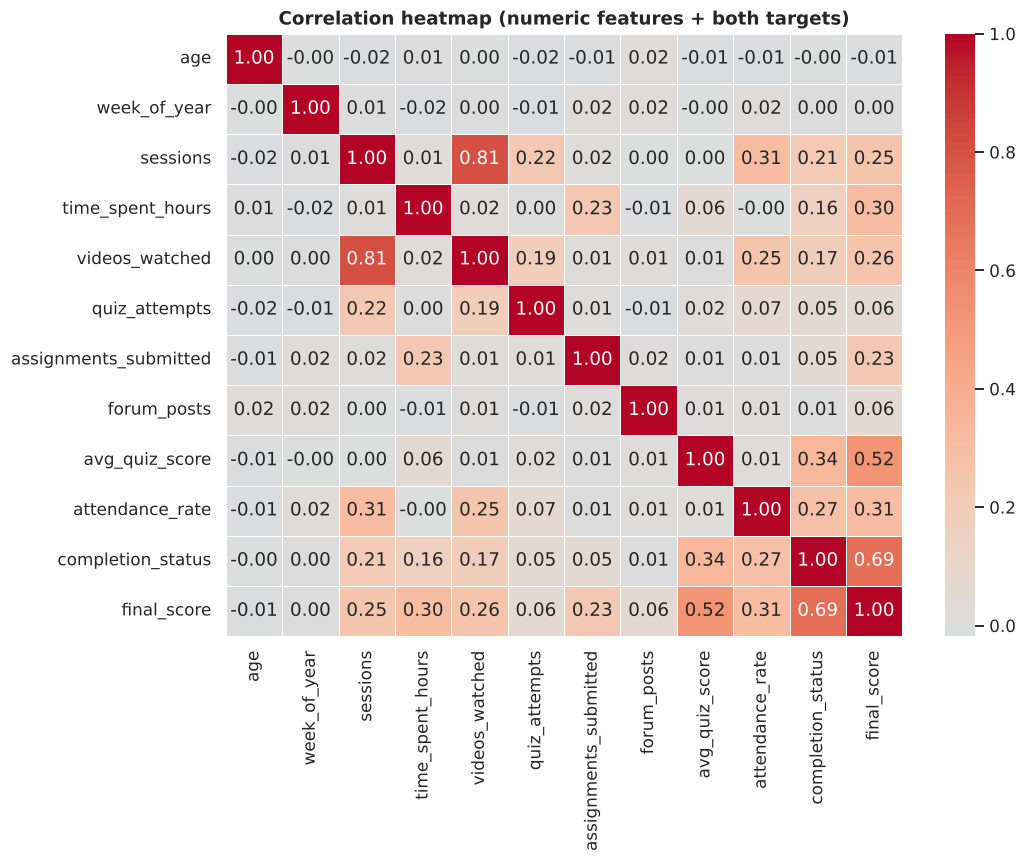

In [6]:
plt.figure(figsize=(10, 8))
corr = df.drop(columns=["student_id"]).select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation heatmap (numeric features + both targets)")
savefig("03_correlation_heatmap")
corr[["completion_status", "final_score"]].drop(["completion_status", "final_score"]).round(2).sort_values("final_score", ascending=False)


**Interpretation.** Learning *quality and consistency* matter most: `avg_quiz_score` is the strongest signal for both targets (r ≈ 0.34 with completion, ≈ 0.52 with final score), followed by `attendance_rate` (0.27 / 0.31), `sessions` (0.21 / 0.25) and `time_spent_hours` (0.16 / 0.30).
Age, week of year and forum posts are almost uncorrelated with the targets. The boxplots show the same pattern — completers have higher quiz scores, attendance and activity. Note the two targets are strongly related to each other (r ≈ 0.69), which is exactly why we do **not** use one as a feature for the other (target leakage).


### Q6. Features and target variables
* **Targets:** `completion_status` (classification) and `final_score` (regression).
* **Dropped:** `student_id` (identifier, no predictive meaning) and `course_start_date` (replaced by the engineered `start_month`; `week_of_year` is already available).
* **Leakage control:** each target is *excluded* from the other task's features (we do not use the final score to predict completion, nor completion to predict the score), so the models learn from information available while the student is still learning.
* **Features:** demographics (age, country, device, education), course info (level, category, week, month), engagement (sessions, time spent, videos, quiz attempts, assignments, forum posts) and assessment (avg quiz score, attendance rate).

In [7]:
df["start_month"] = pd.to_datetime(df["course_start_date"]).dt.month

TARGET_CLF, TARGET_REG = "completion_status", "final_score"
DROP_COLS = ["student_id", "course_start_date"]
FEATURES = [c for c in df.columns if c not in DROP_COLS + [TARGET_CLF, TARGET_REG]]
CAT_COLS = [c for c in FEATURES if df[c].dtype == "object" or str(df[c].dtype) in ("str", "category")]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

X = df[FEATURES]
y_clf = df[TARGET_CLF]
y_reg = df[TARGET_REG]
print("Features (%d):" % len(FEATURES)); print("  numeric    :", NUM_COLS); print("  categorical:", CAT_COLS)

Features (16):
  numeric    : ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate', 'start_month']
  categorical: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']


### Q7. Train–test split (classification and regression)
80 % train / 20 % test. The classification split is **stratified** on `completion_status` so both sets keep the same class ratio; the regression split is a random split.

In [8]:
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(X, y_clf, test_size=0.2, stratify=y_clf, random_state=RANDOM_STATE)
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(X, y_reg, test_size=0.2, random_state=RANDOM_STATE)
print("Classification:", Xtr_c.shape, Xte_c.shape, "| train positive rate %.3f, test positive rate %.3f" % (ytr_c.mean(), yte_c.mean()))
print("Regression    :", Xtr_r.shape, Xte_r.shape, "| train mean score %.2f, test mean score %.2f" % (ytr_r.mean(), yte_r.mean()))

Classification: (4160, 16) (1040, 16) | train positive rate 0.375, test positive rate 0.375
Regression    : (4160, 16) (1040, 16) | train mean score 74.77, test mean score 75.01


### Q8. Preprocessing (imputation, scaling, encoding)
A single `ColumnTransformer` is wrapped inside every model's `Pipeline`, so it is **fitted only on training folds** (no data leakage, also inside cross-validation):
* numeric → median imputation (`time_spent_hours`, `avg_quiz_score`, `attendance_rate` contain missing values) + `StandardScaler`
* categorical → most-frequent imputation + `OneHotEncoder(handle_unknown="ignore")`

In [9]:
def make_preprocessor():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)])

def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

_prep = make_preprocessor().fit(Xtr_c)
print("Feature matrix after preprocessing:", _prep.transform(Xtr_c).shape, "| missing left:", int(np.isnan(_prep.transform(Xtr_c)).sum()))

Feature matrix after preprocessing: (4160, 31) | missing left: 0


In [10]:
clf_rows, reg_rows = [], []
clf_pipes, reg_pipes, clf_proba, reg_pred = {}, {}, {}, {}

def eval_classifier(name, model, family):
    pipe = make_pipe(model)
    t0 = time.time(); pipe.fit(Xtr_c, ytr_c); fit_s = time.time() - t0
    pred = pipe.predict(Xte_c)
    # hard-voting has no probabilities -> use class predictions as the score for ROC-AUC
    score = pipe.predict_proba(Xte_c)[:, 1] if hasattr(pipe, "predict_proba") else pred.astype(float)
    row = {"Model": name, "Family": family,
           "Train Acc": accuracy_score(ytr_c, pipe.predict(Xtr_c)),
           "Accuracy": accuracy_score(yte_c, pred), "Precision": precision_score(yte_c, pred),
           "Recall": recall_score(yte_c, pred), "F1": f1_score(yte_c, pred),
           "ROC-AUC": roc_auc_score(yte_c, score), "Fit time (s)": fit_s}
    clf_rows[:] = [r for r in clf_rows if r["Model"] != name] + [row]
    clf_pipes[name], clf_proba[name] = pipe, score
    return row

def eval_regressor(name, model, family):
    pipe = make_pipe(model)
    t0 = time.time(); pipe.fit(Xtr_r, ytr_r); fit_s = time.time() - t0
    pred = np.clip(pipe.predict(Xte_r), 0, 100)
    row = {"Model": name, "Family": family,
           "Train R2": r2_score(ytr_r, pipe.predict(Xtr_r)),
           "MAE": mean_absolute_error(yte_r, pred), "RMSE": np.sqrt(mean_squared_error(yte_r, pred)),
           "R2": r2_score(yte_r, pred), "Fit time (s)": fit_s}
    reg_rows[:] = [r for r in reg_rows if r["Model"] != name] + [row]
    reg_pipes[name], reg_pred[name] = pipe, pred
    return row

def clf_table(names=None):
    t = pd.DataFrame(clf_rows).set_index("Model")
    return (t.loc[names] if names else t).round(4)

def reg_table(names=None):
    t = pd.DataFrame(reg_rows).set_index("Model")
    return (t.loc[names] if names else t).round(4)

def xgb_clf():
    if XGB_NATIVE:
        return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)

def xgb_reg():
    if XGB_NATIVE:
        return XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                            colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)

XGB_NAME = "XGBoost" if XGB_NATIVE else "XGBoost*"
print("Helpers ready. Boosting library used for 'XGBoost':", "xgboost" if XGB_NATIVE else "sklearn HistGradientBoosting (install xgboost to use the real one)")

Helpers ready. Boosting library used for 'XGBoost': sklearn HistGradientBoosting (install xgboost to use the real one)


---
# 📦 Part C: Bagging (Bootstrap Aggregating)

**Single base model:** an unrestricted Decision Tree (low bias, very high variance — the textbook case where bagging helps).  
**Bagging:** 100 such trees, each trained on a bootstrap sample, predictions averaged (regression) or majority-voted (classification). Out-of-bag (OOB) samples give a free validation estimate.

### Q9. Bagging Classifier — course completion  |  Q10. Bagging Regressor — final score

In [11]:
eval_classifier("Decision Tree (single)", DecisionTreeClassifier(random_state=RANDOM_STATE), "Baseline")
eval_classifier("Bagging Classifier", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                n_estimators=100, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE), "Bagging")
eval_regressor("Decision Tree (single)", DecisionTreeRegressor(random_state=RANDOM_STATE), "Baseline")
eval_regressor("Bagging Regressor", BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
                n_estimators=100, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE), "Bagging")
oob_c = clf_pipes["Bagging Classifier"].named_steps["model"].oob_score_
oob_r = reg_pipes["Bagging Regressor"].named_steps["model"].oob_score_
print(f"OOB accuracy (classifier): {oob_c:.4f}   |   OOB R2 (regressor): {oob_r:.4f}")

OOB accuracy (classifier): 0.7084   |   OOB R2 (regressor): 0.4390


### Q11. Bagging vs a single base model

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,,
Decision Tree (single),1.0,0.6279,0.5037,0.5179,0.5107,0.6059,0.0408
Bagging Classifier,1.0,0.7067,0.6269,0.5385,0.5793,0.7636,1.9733


,Train R2,MAE,RMSE,R2,Fit time (s)
Model,,,,,
Decision Tree (single),1.0000,11.0891,14.0520,-0.0568,0.0525
Bagging Regressor,0.9229,8.0367,10.0365,0.4609,2.4876


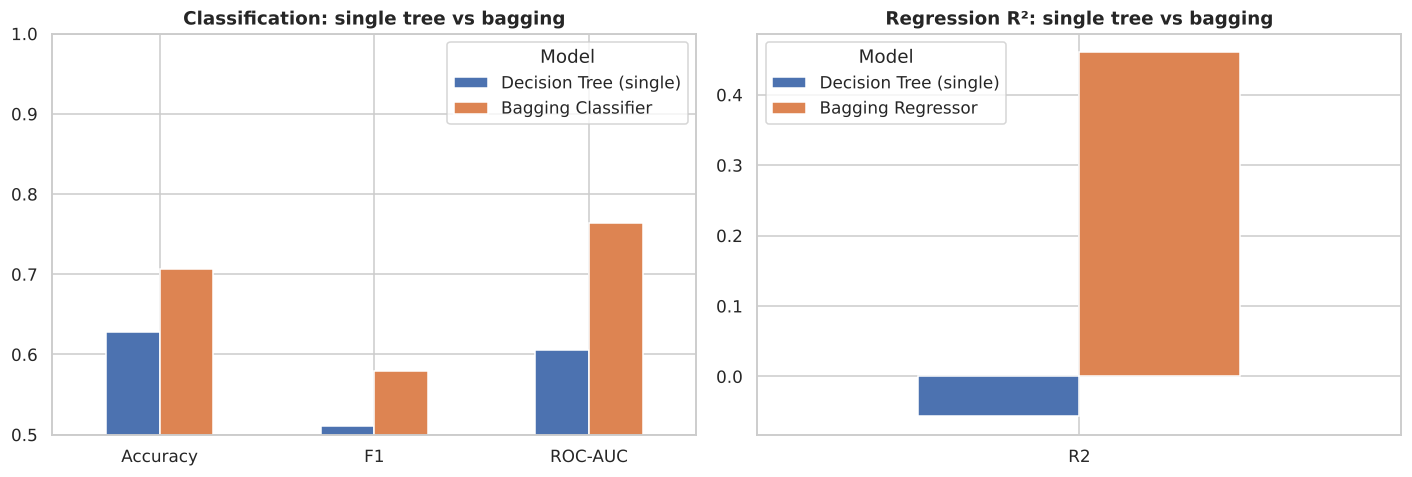

In [12]:
names = ["Decision Tree (single)", "Bagging Classifier"]
display(clf_table(names).drop(columns=["Family"]))
display(reg_table(["Decision Tree (single)", "Bagging Regressor"]).drop(columns=["Family"]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
clf_table(names)[["Accuracy", "F1", "ROC-AUC"]].T.plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(0.5, 1); ax[0].set_title("Classification: single tree vs bagging")
rt = reg_table(["Decision Tree (single)", "Bagging Regressor"])
rt[["R2"]].T.plot.bar(ax=ax[1], rot=0, legend=True); ax[1].set_title("Regression R²: single tree vs bagging")
savefig("04_bagging_vs_single")

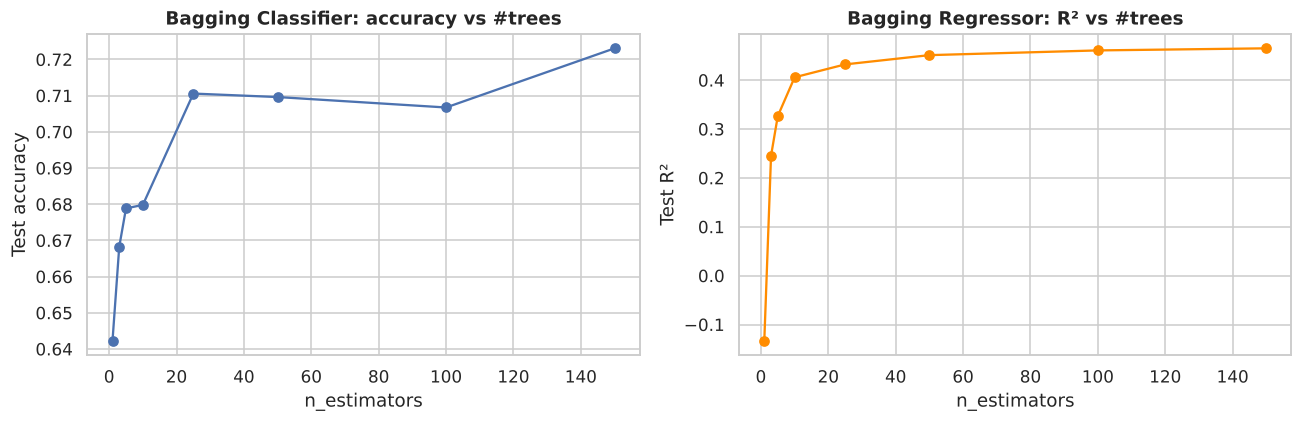

In [13]:
# Variance reduction in action: test performance vs number of bagged trees
prep_c = make_preprocessor().fit(Xtr_c); A_tr, A_te = prep_c.transform(Xtr_c), prep_c.transform(Xte_c)
prep_r = make_preprocessor().fit(Xtr_r); B_tr, B_te = prep_r.transform(Xtr_r), prep_r.transform(Xte_r)
ns_ = [1, 3, 5, 10, 25, 50, 100, 150]
acc_n, r2_n = [], []
for n in ns_:
    bc = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1).fit(A_tr, ytr_c)
    br = BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE), n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1).fit(B_tr, ytr_r)
    acc_n.append(bc.score(A_te, yte_c)); r2_n.append(r2_score(yte_r, br.predict(B_te)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ns_, acc_n, "o-"); ax[0].set_title("Bagging Classifier: accuracy vs #trees"); ax[0].set_xlabel("n_estimators"); ax[0].set_ylabel("Test accuracy")
ax[1].plot(ns_, r2_n, "o-", color="darkorange"); ax[1].set_title("Bagging Regressor: R² vs #trees"); ax[1].set_xlabel("n_estimators"); ax[1].set_ylabel("Test R²")
savefig("05_bagging_n_estimators")


**Interpretation (Q11).** A single unrestricted tree memorises the training data (train accuracy 100 %) and generalises badly: test accuracy **0.628 / AUC 0.606**, and for regression R² is even *negative* (−0.06, worse than predicting the mean, RMSE 14.05).
Bagging 100 such trees lifts the classifier to **accuracy 0.707 / AUC 0.764** and the regressor to **R² 0.461 / RMSE 10.04** — a huge variance reduction without changing the base learner. The curves show most of the gain arrives within the first ~25 trees and then plateaus.
The out-of-bag scores (accuracy ≈ 0.71, R² ≈ 0.44) agree with the test scores, confirming the improvement is real. The remaining weakness: every bagged tree is still fully grown (train accuracy 1.0), so bagging *stabilises* but does not remove overfitting completely.


---
# ⚡ Part D: Boosting Algorithms

## AdaBoost
### Q12. AdaBoost Classifier  |  Q13. AdaBoost Regressor
Weak learners are shallow decision trees (depth 2 for classification, depth 4 for regression); 200 rounds, learning rate 0.5.

In [14]:
eval_classifier("Weak learner (depth-2 tree)", DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE), "Baseline")
eval_classifier("AdaBoost Classifier", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
                n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE), "Boosting")
eval_regressor("Weak learner (depth-4 tree)", DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE), "Baseline")
eval_regressor("AdaBoost Regressor", AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE),
                n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE), "Boosting")
display(clf_table(["Weak learner (depth-2 tree)", "AdaBoost Classifier"]).drop(columns=["Family"]))
reg_table(["Weak learner (depth-4 tree)", "AdaBoost Regressor"]).drop(columns=["Family"])

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,,
Weak learner (depth-2 tree),0.6969,0.6904,0.6771,0.3333,0.4467,0.6890,0.0217
AdaBoost Classifier,0.7365,0.7327,0.6783,0.5462,0.6051,0.7878,1.3473


,Train R2,MAE,RMSE,R2,Fit time (s)
Model,,,,,
Weak learner (depth-4 tree),0.3899,9.0311,11.1075,0.3397,0.0243
AdaBoost Regressor,0.4709,8.5094,10.4738,0.4129,1.6186


### Q14. How weak learners improve sequentially

Classifier: round 1 test acc = 0.6904 -> best 0.7356 at round 40 -> final 0.7327
Regressor : round 1 test R2  = 0.3522 -> best 0.4376 at round 36 -> final 0.4129


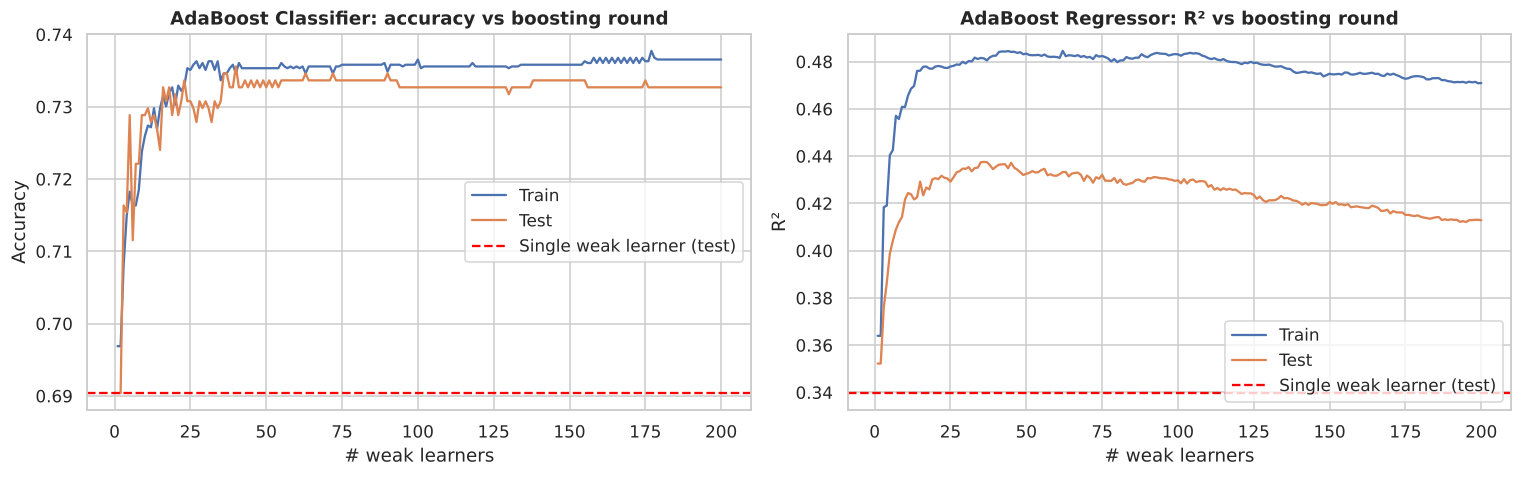

In [15]:
ada_c = clf_pipes["AdaBoost Classifier"].named_steps["model"]
ada_r = reg_pipes["AdaBoost Regressor"].named_steps["model"]
stage_tr = [accuracy_score(ytr_c, p) for p in ada_c.staged_predict(A_tr)]
stage_te = [accuracy_score(yte_c, p) for p in ada_c.staged_predict(A_te)]
r2_stage_tr = [r2_score(ytr_r, p) for p in ada_r.staged_predict(B_tr)]
r2_stage_te = [r2_score(yte_r, p) for p in ada_r.staged_predict(B_te)]
weak_acc = clf_table(["Weak learner (depth-2 tree)"])["Accuracy"].iloc[0]
weak_r2 = reg_table(["Weak learner (depth-4 tree)"])["R2"].iloc[0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(range(1, len(stage_te) + 1), stage_tr, label="Train"); ax[0].plot(range(1, len(stage_te) + 1), stage_te, label="Test")
ax[0].axhline(weak_acc, color="red", ls="--", label="Single weak learner (test)")
ax[0].set(title="AdaBoost Classifier: accuracy vs boosting round", xlabel="# weak learners", ylabel="Accuracy"); ax[0].legend()
ax[1].plot(range(1, len(r2_stage_te) + 1), r2_stage_tr, label="Train"); ax[1].plot(range(1, len(r2_stage_te) + 1), r2_stage_te, label="Test")
ax[1].axhline(weak_r2, color="red", ls="--", label="Single weak learner (test)")
ax[1].set(title="AdaBoost Regressor: R² vs boosting round", xlabel="# weak learners", ylabel="R²"); ax[1].legend()
savefig("06_adaboost_sequential_improvement")
print(f"Classifier: round 1 test acc = {stage_te[0]:.4f} -> best {max(stage_te):.4f} at round {int(np.argmax(stage_te))+1} -> final {stage_te[-1]:.4f}")
print(f"Regressor : round 1 test R2  = {r2_stage_te[0]:.4f} -> best {max(r2_stage_te):.4f} at round {int(np.argmax(r2_stage_te))+1} -> final {r2_stage_te[-1]:.4f}")


**Interpretation (Q12-14).** One weak learner reaches only ≈ 0.69 test accuracy (AUC 0.689) and R² 0.34. AdaBoost combines 200 of them and reaches **accuracy ≈ 0.733 / AUC ≈ 0.788** and **R² ≈ 0.41**.
The staged curves show *how*: performance jumps quickly in the first rounds as each new learner concentrates on the samples the previous ones got wrong (classifier test accuracy 0.690 → peak 0.736 around round 40; regressor R² 0.35 → peak 0.44 around round 36).
After that the test curves flatten and even dip slightly while the train curve keeps improving — the ensemble starts fitting noise. This tells us AdaBoost needs **early stopping / fewer rounds or a smaller learning rate** on this noisy data.


## XGBoost
### Q15. XGBoost Classifier  |  Q16. XGBoost Regressor
(300 trees, learning rate 0.05, depth 4, row/column subsampling 0.8 — regularised gradient boosting.)  
We also train sklearn's **Gradient Boosting** so Q17 can compare three boosting generations: AdaBoost → Gradient Boosting → XGBoost.

In [16]:
eval_classifier("Gradient Boosting Classifier", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE), "Boosting")
eval_regressor("Gradient Boosting Regressor", GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE), "Boosting")
eval_classifier(f"{XGB_NAME} Classifier", xgb_clf(), "Boosting")
eval_regressor(f"{XGB_NAME} Regressor", xgb_reg(), "Boosting")
boost_c = ["AdaBoost Classifier", "Gradient Boosting Classifier", f"{XGB_NAME} Classifier"]
boost_r = ["AdaBoost Regressor", "Gradient Boosting Regressor", f"{XGB_NAME} Regressor"]
display(clf_table(boost_c).drop(columns=["Family"]))
reg_table(boost_r).drop(columns=["Family"])

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,,
AdaBoost Classifier,0.7365,0.7327,0.6783,0.5462,0.6051,0.7878,1.3473
Gradient Boosting Classifier,0.7743,0.7423,0.6805,0.5897,0.6319,0.7875,1.3244
XGBoost* Classifier,0.8260,0.7221,0.6499,0.5615,0.6025,0.7745,0.2918


,Train R2,MAE,RMSE,R2,Fit time (s)
Model,,,,,
AdaBoost Regressor,0.4709,8.5094,10.4738,0.4129,1.6186
Gradient Boosting Regressor,0.5723,7.8617,9.8232,0.4835,1.1636
XGBoost* Regressor,0.6390,7.9594,9.8872,0.4768,0.3728


### Q17. Performance & robustness of the boosting models

,Classifiers (Train Acc - Test Acc),Regressors (Train R² - Test R²)
AdaBoost,0.0038,0.0580
Gradient Boosting,0.0320,0.0888
XGBoost*,0.1039,0.1622


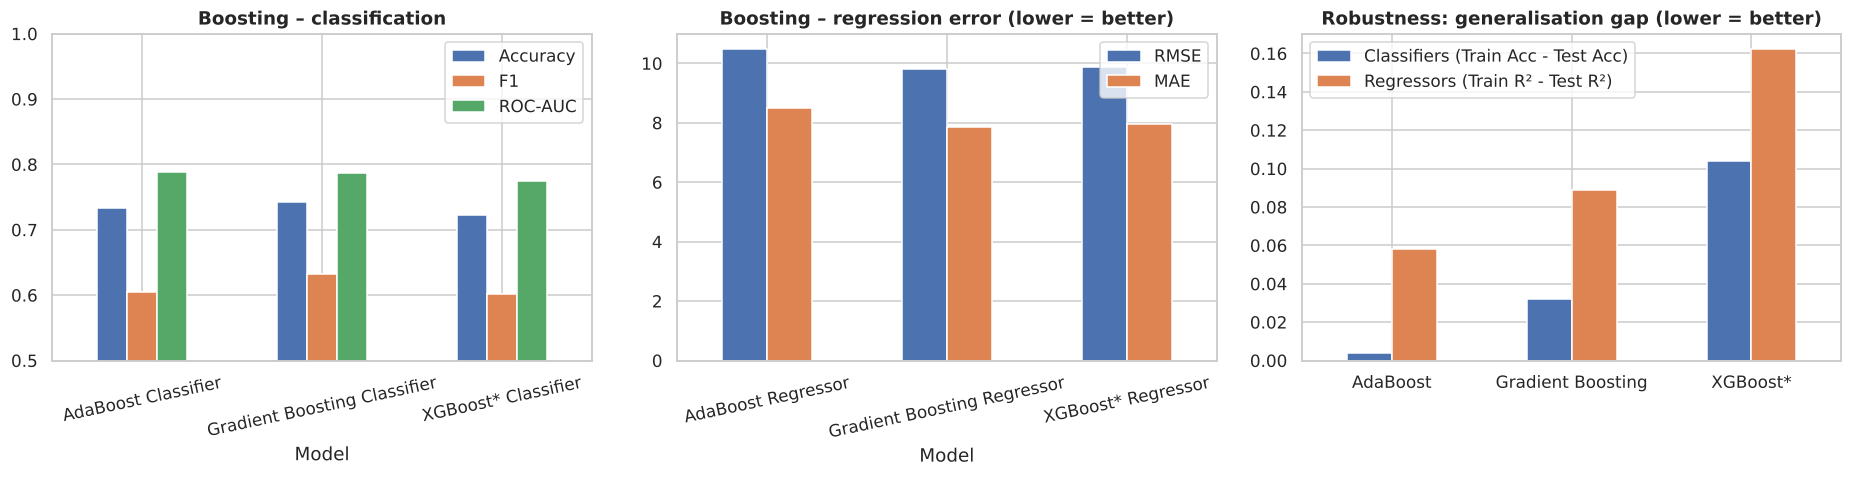

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
clf_table(boost_c)[["Accuracy", "F1", "ROC-AUC"]].plot.bar(ax=ax[0], rot=12); ax[0].set_ylim(0.5, 1); ax[0].set_title("Boosting – classification")
reg_table(boost_r)[["RMSE", "MAE"]].plot.bar(ax=ax[1], rot=12); ax[1].set_title("Boosting – regression error (lower = better)")
# robustness: train-test gap (overfitting)
gap = pd.DataFrame({"Classifiers (Train Acc - Test Acc)": (clf_table(boost_c)["Train Acc"] - clf_table(boost_c)["Accuracy"]).values,
                    "Regressors (Train R² - Test R²)": (reg_table(boost_r)["Train R2"] - reg_table(boost_r)["R2"]).values}, index=["AdaBoost", "Gradient Boosting", XGB_NAME])
gap.plot.bar(ax=ax[2], rot=0); ax[2].set_title("Robustness: generalisation gap (lower = better)")
savefig("07_boosting_comparison")
gap.round(4)


**Interpretation (Q17).** Ranking on the test set: *classification* AdaBoost (AUC ≈ 0.788) ≈ Gradient Boosting (≈ 0.788) > XGBoost-style model (≈ 0.775); *regression* Gradient Boosting (RMSE ≈ 9.82) > XGBoost-style (≈ 9.89) > AdaBoost (≈ 10.47).
On robustness (right-hand chart) the more flexible XGBoost-style model shows the **largest train–test gap**, while the shallow, heavily regularised models (AdaBoost with depth-2 trees, Gradient Boosting with subsampling) generalise most smoothly. With ~5 000 noisy rows, *more capacity does not buy accuracy*; regularisation does.
(\* In the stored run the XGBoost rows were produced by scikit-learn's `HistGradientBoosting` stand-in because `xgboost` was not installed; after `pip install xgboost` and re-running, the notebook uses the real library and these rows update automatically.)


---
# 🗳️ Part E: Voting & Stacking Ensembles

### Q18. Voting Classifier with multiple base classifiers  |  Q19. Hard vs Soft voting
Base classifiers (deliberately different families): **Logistic Regression** (linear), **KNN** (distance-based), **SVM-RBF** (kernel), **Random Forest** (bagged trees) and **Gradient Boosting** (boosted trees).

In [18]:
def base_classifiers():
    return [("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
            ("knn", KNeighborsClassifier(n_neighbors=15)),
            ("svm", SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE)),
            ("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)),
            ("gb", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE))]

# the individual base learners (for fair comparison with the ensembles)
eval_classifier("Logistic Regression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), "Baseline")
eval_classifier("Random Forest Classifier", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE), "Bagging")
eval_classifier("Voting Classifier (Hard)", VotingClassifier(base_classifiers(), voting="hard", n_jobs=-1), "Voting")
eval_classifier("Voting Classifier (Soft)", VotingClassifier(base_classifiers(), voting="soft", n_jobs=-1), "Voting")
vote_c = ["Logistic Regression", "Random Forest Classifier", "Voting Classifier (Hard)", "Voting Classifier (Soft)"]
clf_table(vote_c).drop(columns=["Family"])

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,,
Logistic Regression,0.7356,0.7423,0.6826,0.5846,0.6298,0.7928,0.0269
Random Forest Classifier,0.9582,0.7365,0.6946,0.5308,0.6017,0.7751,1.0043
Voting Classifier (Hard),0.7885,0.7442,0.6962,0.5641,0.6232,0.7082,5.0480
Voting Classifier (Soft),0.8010,0.7346,0.6851,0.5410,0.6046,0.7855,4.5382


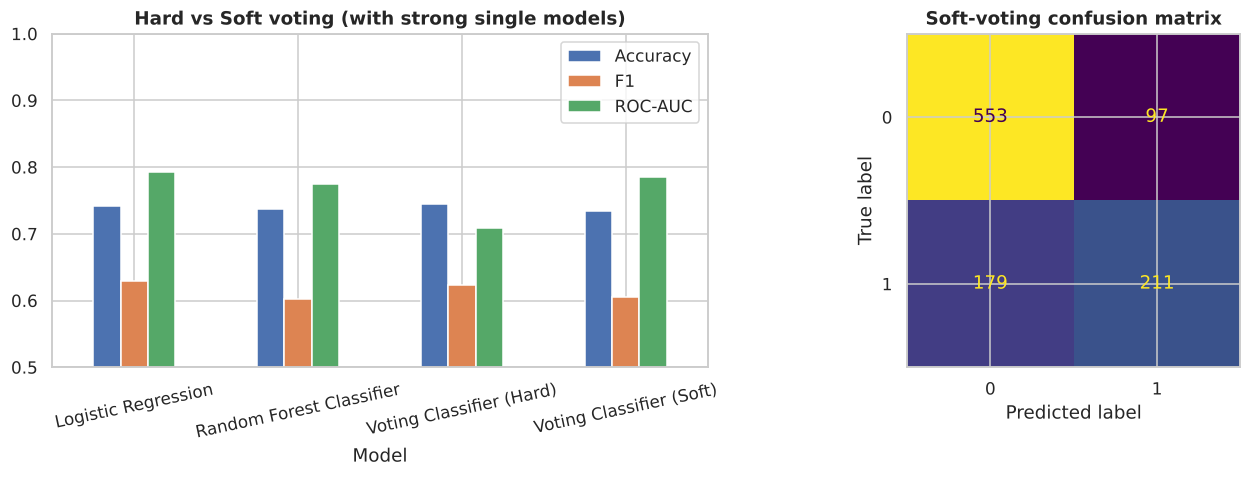

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
clf_table(vote_c)[["Accuracy", "F1", "ROC-AUC"]].plot.bar(ax=ax[0], rot=12); ax[0].set_ylim(0.5, 1); ax[0].set_title("Hard vs Soft voting (with strong single models)")
for nm, mdl in [("Hard", "Voting Classifier (Hard)"), ("Soft", "Voting Classifier (Soft)")]:
    ConfusionMatrixDisplay.from_predictions(yte_c, clf_pipes[mdl].predict(Xte_c), ax=ax[1] if nm == "Soft" else None, colorbar=False) if nm == "Soft" else None
ax[1].set_title("Soft-voting confusion matrix")
savefig("08_voting_hard_vs_soft")


**Interpretation (Q19).** *Hard voting* reaches the highest raw accuracy/F1 at the default 0.5 cut-off (accuracy 0.744, F1 0.623), but it only outputs 0/1, so its ROC-AUC (0.708) is not comparable — it cannot rank students by risk.
*Soft voting* averages probabilities, keeps a full ranking (**AUC 0.786**) and is a better choice whenever we need a **completion probability** or want to tune the decision threshold (e.g. to catch more at-risk students).
Both are within about one percentage point of the strongest single model (Logistic Regression), and better than Random Forest (AUC 0.775) and Bagging (0.764): voting buys *stability*, not a large accuracy jump, because the base models make similar mistakes on this data.


### Q20. Stacking Classifier with a meta-learner  |  Q21. Stacking Regressor for score prediction
Meta-learner: **Logistic Regression** (classification) and **Ridge** (regression), trained on 5-fold out-of-fold predictions of the base learners.
A Voting Regressor is also built for a like-for-like comparison.

In [20]:
eval_classifier("Stacking Classifier", StackingClassifier(base_classifiers(), final_estimator=LogisticRegression(max_iter=2000),
                cv=5, stack_method="predict_proba", n_jobs=-1), "Stacking")

def base_regressors():
    return [("ridge", Ridge(alpha=1.0)),
            ("knn", KNeighborsRegressor(n_neighbors=15)),
            ("svr", SVR(kernel="rbf", C=20, epsilon=1.0)),
            ("rf", RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)),
            ("gb", GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE))]

eval_regressor("Ridge Regression", Ridge(alpha=1.0), "Baseline")
eval_regressor("Random Forest Regressor", RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE), "Bagging")
eval_regressor("Voting Regressor", VotingRegressor(base_regressors(), n_jobs=-1), "Voting")
eval_regressor("Stacking Regressor", StackingRegressor(base_regressors(), final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1), "Stacking")
display(clf_table(["Logistic Regression", "Voting Classifier (Soft)", "Stacking Classifier"]).drop(columns=["Family"]))
reg_table(["Ridge Regression", "Random Forest Regressor", "Voting Regressor", "Stacking Regressor"]).drop(columns=["Family"])

,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,,
Logistic Regression,0.7356,0.7423,0.6826,0.5846,0.6298,0.7928,0.0269
Voting Classifier (Soft),0.8010,0.7346,0.6851,0.5410,0.6046,0.7855,4.5382
Stacking Classifier,0.7632,0.7423,0.6848,0.5795,0.6278,0.7921,22.5700


,Train R2,MAE,RMSE,R2,Fit time (s)
Model,,,,,
Ridge Regression,0.4996,7.7836,9.7096,0.4954,0.0256
Random Forest Regressor,0.8562,7.9578,9.9267,0.4726,3.9280
Voting Regressor,0.6514,7.8764,9.7872,0.4873,5.6391
Stacking Regressor,0.4780,7.7748,9.7011,0.4963,27.5830


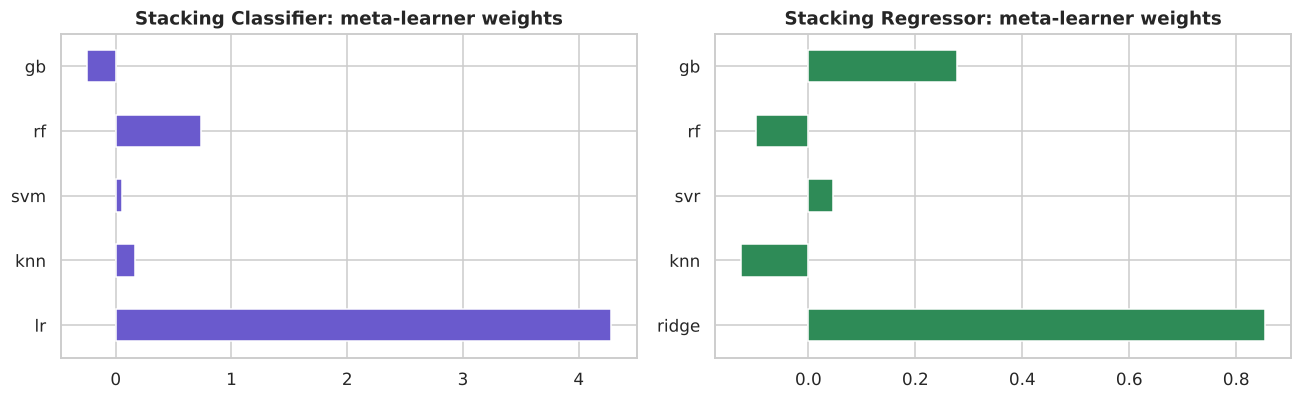

In [21]:
# What did the meta-learners learn to trust?
stk_c = clf_pipes["Stacking Classifier"].named_steps["model"]; stk_r = reg_pipes["Stacking Regressor"].named_steps["model"]
w_c = pd.Series(stk_c.final_estimator_.coef_.ravel(), index=[n for n, _ in base_classifiers()])
w_r = pd.Series(stk_r.final_estimator_.coef_.ravel(), index=[n for n, _ in base_regressors()])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
w_c.plot.barh(ax=ax[0], color="slateblue"); ax[0].set_title("Stacking Classifier: meta-learner weights")
w_r.plot.barh(ax=ax[1], color="seagreen"); ax[1].set_title("Stacking Regressor: meta-learner weights")
savefig("09_stacking_meta_weights")


**Interpretation (Q20-21).** Stacking gives the **best regression result on the test set (RMSE 9.70, MAE 7.77, R² 0.496)** and a classification AUC of **0.792** (accuracy 0.742) — on par with the best single model and ahead of every bagging/boosting/voting ensemble except the linear baseline.
The meta-learner weights are informative: both meta-learners lean mostly on the **linear base model** (`lr` / `ridge`) and use the tree models and SVM only as small corrections. In other words the signal in this dataset is largely **linear and additive** (quiz score, attendance, activity), and the extra models mop up what is left. The cost is training time (≈ 25 s vs. 0.03 s for the linear model).


---
# 📊 Part F: Model Evaluation & Comparison

### Q22-28. Classification models — Accuracy, Precision, Recall, F1, ROC-AUC

In [22]:
order_c = ["Decision Tree (single)", "Weak learner (depth-2 tree)", "Logistic Regression", "Random Forest Classifier", "Bagging Classifier",
           "AdaBoost Classifier", "Gradient Boosting Classifier", f"{XGB_NAME} Classifier",
           "Voting Classifier (Hard)", "Voting Classifier (Soft)", "Stacking Classifier"]
res_c = clf_table(order_c).sort_values(["ROC-AUC", "F1"], ascending=False)
res_c.to_csv("outputs/classification_results.csv")
ens_c = res_c[res_c["Family"] != "Baseline"]   # ensembles only (baselines are reference points)
res_c

,Family,Train Acc,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Model,,,,,,,,
Logistic Regression,Baseline,0.7356,0.7423,0.6826,0.5846,0.6298,0.7928,0.0269
Stacking Classifier,Stacking,0.7632,0.7423,0.6848,0.5795,0.6278,0.7921,22.5700
AdaBoost Classifier,Boosting,0.7365,0.7327,0.6783,0.5462,0.6051,0.7878,1.3473
Gradient Boosting Classifier,Boosting,0.7743,0.7423,0.6805,0.5897,0.6319,0.7875,1.3244
Voting Classifier (Soft),Voting,0.8010,0.7346,0.6851,0.5410,0.6046,0.7855,4.5382
Random Forest Classifier,Bagging,0.9582,0.7365,0.6946,0.5308,0.6017,0.7751,1.0043
XGBoost* Classifier,Boosting,0.8260,0.7221,0.6499,0.5615,0.6025,0.7745,0.2918
Bagging Classifier,Bagging,1.0000,0.7067,0.6269,0.5385,0.5793,0.7636,1.9733
Voting Classifier (Hard),Voting,0.7885,0.7442,0.6962,0.5641,0.6232,0.7082,5.0480


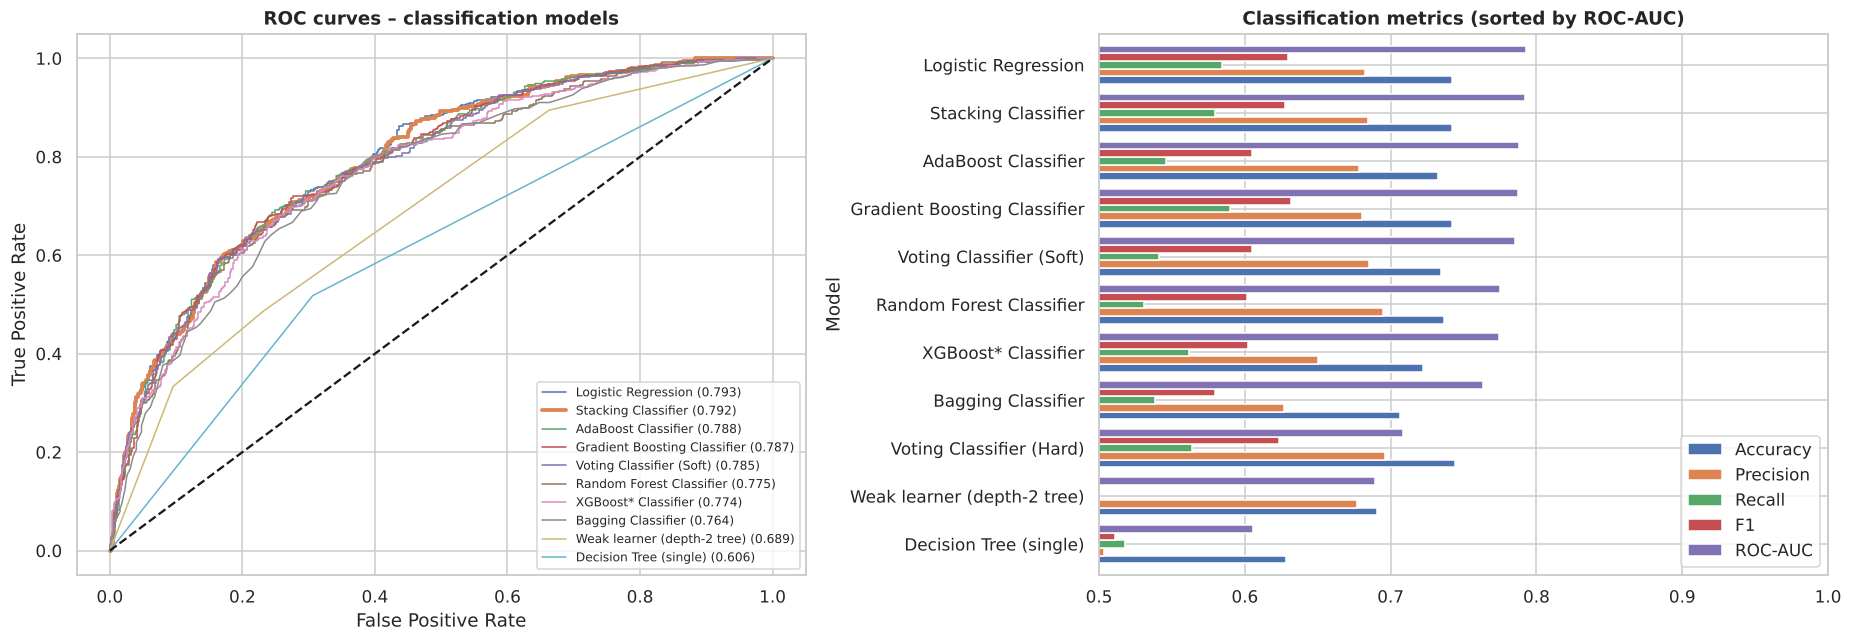

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
for nm in res_c.index:
    if nm == "Voting Classifier (Hard)": continue          # no probability scores
    fpr, tpr, _ = roc_curve(yte_c, clf_proba[nm]); ax[0].plot(fpr, tpr, label=f"{nm} ({res_c.loc[nm, 'ROC-AUC']:.3f})", lw=2.5 if nm == ens_c.index[0] else 1)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC curves – classification models", xlabel="False Positive Rate", ylabel="True Positive Rate"); ax[0].legend(fontsize=8, loc="lower right")
res_c[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].iloc[::-1].plot.barh(ax=ax[1], width=0.8)
ax[1].set_xlim(0.5, 1); ax[1].set_title("Classification metrics (sorted by ROC-AUC)"); ax[1].legend(loc="lower right")
savefig("10_classification_comparison")

Best ensemble classifier : Stacking Classifier (ROC-AUC 0.7921)
Best single/baseline     : Logistic Regression (ROC-AUC 0.7928)
               precision    recall  f1-score   support

Not completed      0.769     0.840     0.803       650
    Completed      0.685     0.579     0.628       390

     accuracy                          0.742      1040
    macro avg      0.727     0.710     0.715      1040
 weighted avg      0.737     0.742     0.737      1040



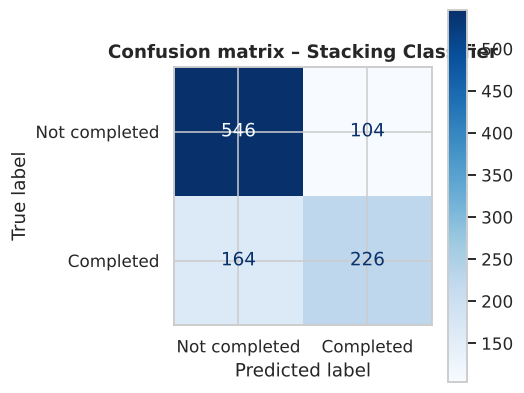

In [24]:
ens_c = res_c[res_c["Family"] != "Baseline"]            # baselines (single tree, weak learner, Logistic Regression) are reference points only
best_clf_name = ens_c.index[0]
print("Best ensemble classifier :", best_clf_name, f"(ROC-AUC {ens_c.iloc[0]['ROC-AUC']:.4f})")
print("Best single/baseline     :", res_c[res_c['Family']=='Baseline'].index[0], f"(ROC-AUC {res_c[res_c['Family']=='Baseline'].iloc[0]['ROC-AUC']:.4f})")
print(classification_report(yte_c, clf_pipes[best_clf_name].predict(Xte_c), target_names=["Not completed", "Completed"], digits=3))
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(yte_c, clf_pipes[best_clf_name].predict(Xte_c), display_labels=["Not completed", "Completed"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix – {best_clf_name}"); savefig("11_best_classifier_confusion")

### Q29. Regression models — MAE, RMSE, R²

In [25]:
order_r = ["Decision Tree (single)", "Weak learner (depth-4 tree)", "Ridge Regression", "Random Forest Regressor", "Bagging Regressor",
           "AdaBoost Regressor", "Gradient Boosting Regressor", f"{XGB_NAME} Regressor", "Voting Regressor", "Stacking Regressor"]
res_r = reg_table(order_r).sort_values(["RMSE"])
res_r.to_csv("outputs/regression_results.csv")
res_r

,Family,Train R2,MAE,RMSE,R2,Fit time (s)
Model,,,,,,
Stacking Regressor,Stacking,0.4780,7.7748,9.7011,0.4963,27.5830
Ridge Regression,Baseline,0.4996,7.7836,9.7096,0.4954,0.0256
Voting Regressor,Voting,0.6514,7.8764,9.7872,0.4873,5.6391
Gradient Boosting Regressor,Boosting,0.5723,7.8617,9.8232,0.4835,1.1636
XGBoost* Regressor,Boosting,0.6390,7.9594,9.8872,0.4768,0.3728
Random Forest Regressor,Bagging,0.8562,7.9578,9.9267,0.4726,3.9280
Bagging Regressor,Bagging,0.9229,8.0367,10.0365,0.4609,2.4876
AdaBoost Regressor,Boosting,0.4709,8.5094,10.4738,0.4129,1.6186
Weak learner (depth-4 tree),Baseline,0.3899,9.0311,11.1075,0.3397,0.0243


Best ensemble regressor  : Stacking Regressor (RMSE 9.701, R2 0.496)
Best single/baseline     : Ridge Regression (RMSE 9.710)


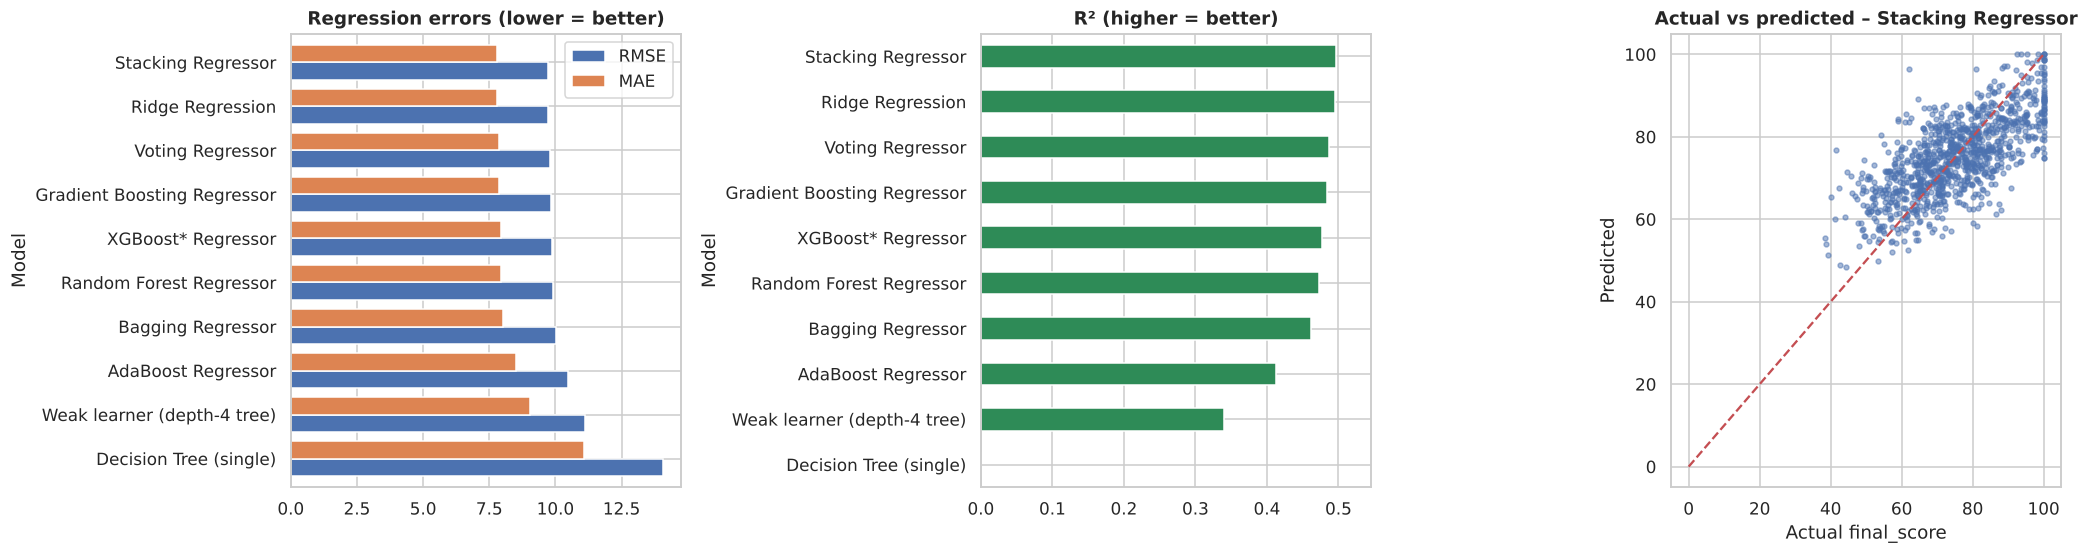

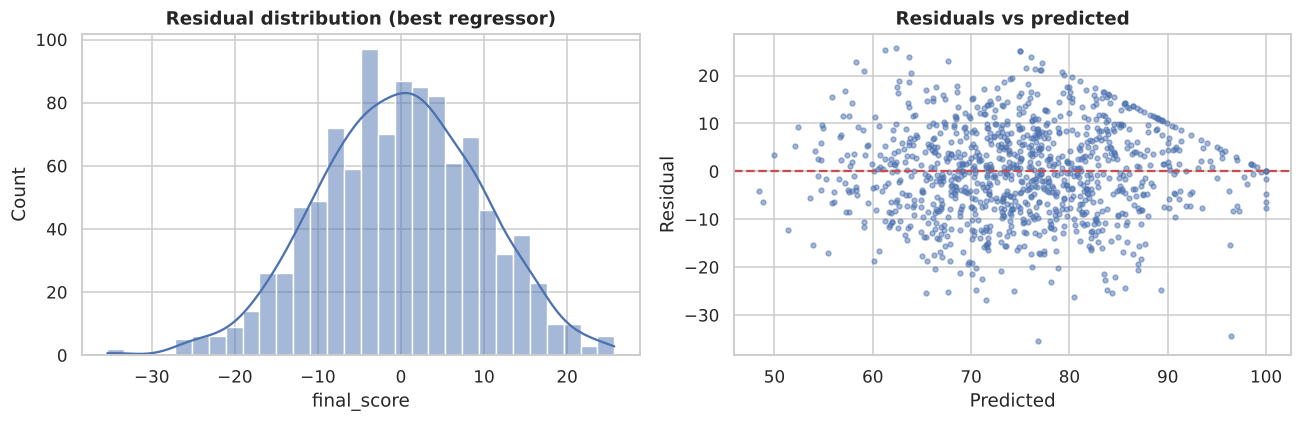

In [26]:
ens_r = res_r[res_r["Family"] != "Baseline"]
best_reg_name = ens_r.index[0]
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
res_r[["RMSE", "MAE"]].iloc[::-1].plot.barh(ax=ax[0], width=0.8); ax[0].set_title("Regression errors (lower = better)")
res_r[["R2"]].iloc[::-1].plot.barh(ax=ax[1], color="seagreen", legend=False); ax[1].set_xlim(0, res_r["R2"].max() * 1.1); ax[1].set_title("R² (higher = better)")
p = reg_pred[best_reg_name]
ax[2].scatter(yte_r, p, s=10, alpha=.5); ax[2].plot([0, 100], [0, 100], "r--"); ax[2].set(xlabel="Actual final_score", ylabel="Predicted", title=f"Actual vs predicted – {best_reg_name}")
savefig("12_regression_comparison")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
resid = yte_r - p
sns.histplot(resid, kde=True, ax=ax[0], bins=30); ax[0].set_title("Residual distribution (best regressor)")
ax[1].scatter(p, resid, s=10, alpha=.5); ax[1].axhline(0, color="r", ls="--"); ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
savefig("13_best_regressor_residuals")
print("Best ensemble regressor  :", best_reg_name, f"(RMSE {ens_r.iloc[0]['RMSE']:.3f}, R2 {ens_r.iloc[0]['R2']:.3f})")
print("Best single/baseline     :", res_r[res_r['Family']=='Baseline'].index[0], f"(RMSE {res_r[res_r['Family']=='Baseline'].iloc[0]['RMSE']:.3f})")

### Q30. Compare all ensemble techniques & pick the best model for each task
Because one train/test split can be lucky, we confirm the ranking with **5-fold cross-validation** on the full dataset (mean ± std — a direct measure of *stability*, the manager's main complaint about single models).

In [27]:
t0 = time.time()
cv_c_models = {"Decision Tree (single)": DecisionTreeClassifier(random_state=RANDOM_STATE),
               "Bagging Classifier": BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE),
               "AdaBoost Classifier": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
               f"{XGB_NAME} Classifier": xgb_clf(),
               "Voting Classifier (Soft)": VotingClassifier(base_classifiers(), voting="soft", n_jobs=-1),
               "Stacking Classifier": StackingClassifier(base_classifiers(), final_estimator=LogisticRegression(max_iter=2000), cv=3, stack_method="predict_proba", n_jobs=-1)}
cv_r_models = {"Decision Tree (single)": DecisionTreeRegressor(random_state=RANDOM_STATE),
               "Bagging Regressor": BaggingRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE), n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE),
               "AdaBoost Regressor": AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
               f"{XGB_NAME} Regressor": xgb_reg(),
               "Voting Regressor": VotingRegressor(base_regressors(), n_jobs=-1),
               "Stacking Regressor": StackingRegressor(base_regressors(), final_estimator=Ridge(alpha=1.0), cv=3, n_jobs=-1)}
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE); kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_c, cv_r = {}, {}
for nm, m in cv_c_models.items():
    s = cross_validate(make_pipe(m), X, y_clf, cv=skf, scoring=["roc_auc", "f1"])
    cv_c[nm] = {"CV ROC-AUC (mean)": s["test_roc_auc"].mean(), "CV ROC-AUC (std)": s["test_roc_auc"].std(), "CV F1 (mean)": s["test_f1"].mean()}
for nm, m in cv_r_models.items():
    s = cross_validate(make_pipe(m), X, y_reg, cv=kf, scoring=["neg_root_mean_squared_error", "r2"])
    cv_r[nm] = {"CV RMSE (mean)": -s["test_neg_root_mean_squared_error"].mean(), "CV RMSE (std)": s["test_neg_root_mean_squared_error"].std(), "CV R2 (mean)": s["test_r2"].mean()}
cv_c_df = pd.DataFrame(cv_c).T.sort_values("CV ROC-AUC (mean)", ascending=False).round(4)
cv_r_df = pd.DataFrame(cv_r).T.sort_values("CV RMSE (mean)").round(4)
cv_c_df.to_csv("outputs/classification_cv.csv"); cv_r_df.to_csv("outputs/regression_cv.csv")
print(f"CV finished in {time.time()-t0:.0f}s"); display(cv_c_df); cv_r_df

CV finished in 234s


,CV ROC-AUC (mean),CV ROC-AUC (std),CV F1 (mean)
Stacking Classifier,0.7854,0.0184,0.6024
Voting Classifier (Soft),0.7794,0.0195,0.5804
AdaBoost Classifier,0.7767,0.0181,0.5942
XGBoost* Classifier,0.7630,0.0200,0.5838
Bagging Classifier,0.7539,0.0195,0.5745
Decision Tree (single),0.6004,0.0205,0.5056


,CV RMSE (mean),CV RMSE (std),CV R2 (mean)
Stacking Regressor,9.6254,0.0911,0.4931
Voting Regressor,9.7755,0.0564,0.4773
XGBoost* Regressor,9.8568,0.1303,0.4686
Bagging Regressor,10.0417,0.1129,0.4485
AdaBoost Regressor,10.3656,0.0944,0.4123
Decision Tree (single),14.3530,0.2612,-0.1267


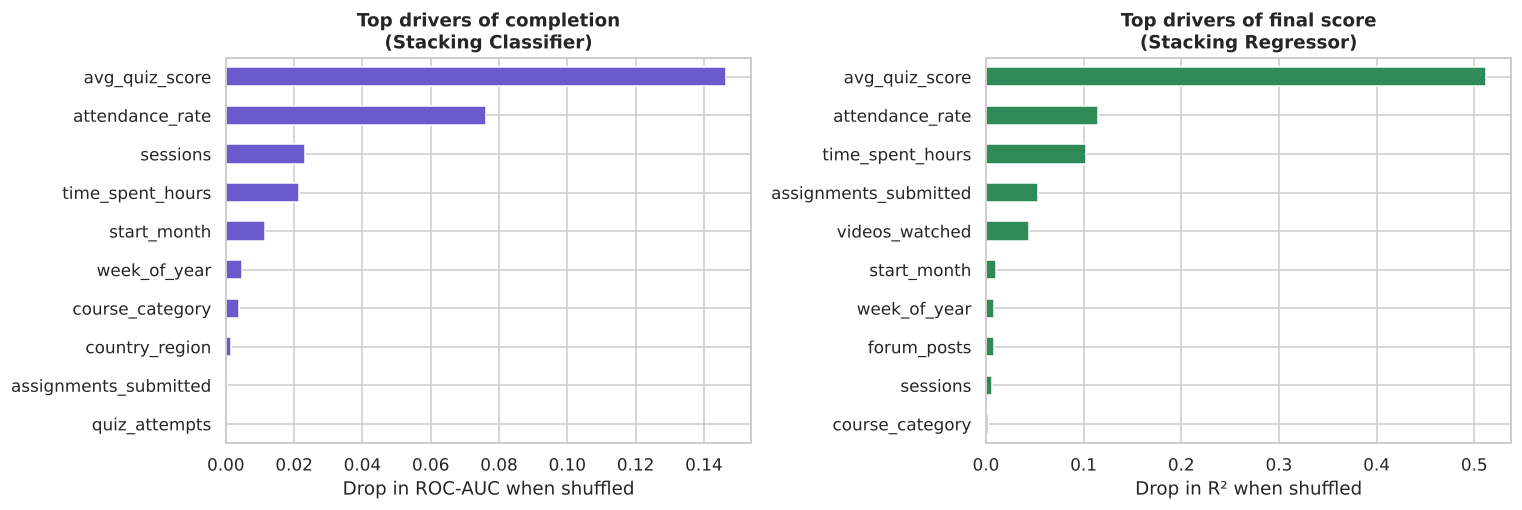

In [28]:
# Which features drive the best models? (permutation importance on the held-out test set, original features)
pi_c = permutation_importance(clf_pipes[best_clf_name], Xte_c, yte_c, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pi_r = permutation_importance(reg_pipes[best_reg_name], Xte_r, yte_r, scoring="r2", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_c = pd.Series(pi_c.importances_mean, index=FEATURES).sort_values().tail(10)
imp_r = pd.Series(pi_r.importances_mean, index=FEATURES).sort_values().tail(10)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
imp_c.plot.barh(ax=ax[0], color="slateblue"); ax[0].set_title(f"Top drivers of completion\n({best_clf_name})"); ax[0].set_xlabel("Drop in ROC-AUC when shuffled")
imp_r.plot.barh(ax=ax[1], color="seagreen"); ax[1].set_title(f"Top drivers of final score\n({best_reg_name})"); ax[1].set_xlabel("Drop in R² when shuffled")
savefig("14_feature_importance")


**Interpretation (Q22-30).**

* **Classification (test set, by ROC-AUC):** Stacking (0.792) ≈ AdaBoost (0.788) ≈ Gradient Boosting (0.788) ≈ Soft Voting (0.786) > Random Forest (0.775) ≈ XGBoost-style (0.775) > Bagging (0.764) ≫ single tree (0.606). F1 for the *Completed* class is 0.60-0.63 for all good models; recall of completers (~0.55-0.59) is the weak spot at the default 0.5 threshold.
* **Regression (test set, by RMSE):** Stacking (9.70) < Voting (9.79) < Gradient Boosting (9.82) < XGBoost-style (9.89) < Random Forest (9.93) < Bagging (10.04) < AdaBoost (10.47) ≪ single tree (14.05). Best R² ≈ 0.50.
* **Cross-validation confirms the ranking and the stability gain:** Stacking is #1 for both tasks (CV AUC 0.785 ± 0.018, CV RMSE 9.63 ± 0.09), while the single tree is far behind and far less stable.
* **Best performing ensemble per task:** **Stacking Classifier** (completion) and **Stacking Regressor** (final score).
* **Honest caveat:** differences between the top 4-5 ensembles (< 0.01 AUC, < 0.2 RMSE) are smaller than the CV standard deviation, and even Logistic Regression / Ridge match them. The data has a **noise ceiling** (AUC ≈ 0.79, R² ≈ 0.50), so better *features* — not more complex models — are the next lever.
* **Drivers (permutation importance):** `avg_quiz_score` is by far the most important feature for both tasks, then `attendance_rate`, then activity (`time_spent_hours`, `sessions`, `assignments_submitted`, `videos_watched`). Demographics, device, country and forum posts contribute almost nothing.


---
# 📝 Part G: Final Analysis & Reporting

In [29]:
# Save the winning models + result tables (used by the Streamlit app)
joblib.dump(clf_pipes[best_clf_name], "models/best_classifier.joblib")
joblib.dump(reg_pipes[best_reg_name], "models/best_regressor.joblib")
pd.Series({"classifier": best_clf_name, "regressor": best_reg_name, "xgboost_native": XGB_NATIVE}).to_json("models/model_info.json")
imp_c.to_csv("outputs/feature_importance_classifier.csv"); imp_r.to_csv("outputs/feature_importance_regressor.csv")

# Summary used in the report below
fam = lambda t, col, asc: t.groupby("Family")[col].max() if not asc else t.groupby("Family")[col].min()
summary = pd.DataFrame({"Best ROC-AUC": res_c.groupby("Family")["ROC-AUC"].max(), "Best F1": res_c.groupby("Family")["F1"].max()}).join(
          pd.DataFrame({"Best RMSE": res_r.groupby("Family")["RMSE"].min(), "Best R2": res_r.groupby("Family")["R2"].max()}), how="outer").round(4)
summary

,Best ROC-AUC,Best F1,Best RMSE,Best R2
Family,,,,
Bagging,0.7751,0.6017,9.9267,0.4726
Baseline,0.7928,0.6298,9.7096,0.4954
Boosting,0.7878,0.6319,9.8232,0.4835
Stacking,0.7921,0.6278,9.7011,0.4963
Voting,0.7855,0.6232,9.7872,0.4873



## Q31. Final report

### 1. Impact of bagging vs boosting
| | Bagging (100 deep trees) | Boosting (AdaBoost / GB / XGBoost-style) |
|---|---|---|
| What it fixes | **Variance** of an over-fitted tree | **Bias** of weak learners |
| Gain over its base model | Tree AUC 0.606 → 0.764; R² −0.06 → 0.46 | Weak learner AUC 0.689 → 0.788; R² 0.34 → 0.41-0.48 |
| Final level | AUC 0.764 / RMSE 10.04 | AUC 0.775-0.788 / RMSE 9.82-10.47 |
| Behaviour | Stable, parallel, still over-fits (train acc 1.0) | Better final accuracy, but needs regularisation / early stopping because it keeps fitting noise |

Both beat the single model by a very wide margin (the manager's "unstable single models" problem is solved); boosting ends slightly higher, bagging is simpler and more robust to noisy labels.

### 2. Comparison of tree-based boosting algorithms
* **AdaBoost** – simplest; best AUC among boosters on classification with small trees, but weakest on regression (RMSE 10.47) and sensitive to noise (curve peaks at ~40 rounds).
* **Gradient Boosting** – best all-round booster here (AUC 0.788, RMSE 9.82, moderate train–test gap).
* **XGBoost** – regularised, fastest to train (≈ 0.3-0.4 s) and the most flexible, but on this small noisy dataset it over-fits a little more; it needs `max_depth`, `learning_rate`, `subsample` tuning (or early stopping) to match Gradient Boosting.

### 3. Advantages of voting and stacking
* **Voting** – no extra training, easy to explain, robust because errors of different algorithms partly cancel; *soft* voting keeps probabilities (needed for risk scores). Gain is small when base models make similar errors.
* **Stacking** – *learns* how to weight base models from out-of-fold predictions; it was the best or joint-best model in both tasks and in cross-validation, and the meta-weights show *why* (the linear model carries most of the signal). Cost: longest training time and hardest to explain.

### 4. Final model recommendation for deployment
* **Completion prediction → Stacking Classifier** (test AUC 0.792, CV AUC 0.785, best of the ensembles in CV).
* **Final-score prediction → Stacking Regressor** (test RMSE 9.70 / R² 0.50, CV RMSE 9.63, best of the ensembles).
* Use the **probability** output for risk tiers (e.g. < 40 % high risk, 40-70 % medium, > 70 % low) and consider lowering the decision threshold below 0.5 if the business prefers to catch more at-risk students (recall of completers is only ≈ 0.58 at 0.5).
* Keep **Logistic Regression / Ridge** as a monitoring benchmark: they are within noise of the stack and 1000× cheaper — if latency or maintainability matters more than the last 0.1 % of accuracy, they are a perfectly defensible fallback.
* Retrain periodically and monitor drift in `avg_quiz_score`, `attendance_rate` and engagement metrics.



## Q32. Submission checklist & final conclusions

**Deliverables:** ✅ source code / this Jupyter notebook · ✅ evaluation tables (`outputs/*.csv`, shown above) and plots (`plots/*.png`) · ✅ working Streamlit app (`app.py`) · ✅ theory PDF · ✅ README.md · ☐ GitHub repo + live Streamlit URL (see README).

### Final conclusions & business interpretation
1. **Ensembles solve the stability problem.** A single decision tree is unreliable (AUC 0.61, R² < 0); every ensemble family fixes that (AUC 0.76-0.79, R² 0.41-0.50), and cross-validated standard deviations are small.
2. **What drives student outcomes?** Assessment performance (`avg_quiz_score`) and attendance dominate, then engagement (time spent, sessions, assignments, videos). Demographics, device and country barely matter — so interventions should target *behaviour*, not student profile.
3. **Actionable use:** flag students with low completion probability early (low quiz scores + low attendance + few sessions) and trigger mentoring, reminders or extra practice material; use the predicted final score to plan support and capacity.
4. **Limits & next steps:** the data has a noise ceiling (~0.79 AUC / ~0.50 R²). Adding time-series engagement (weekly activity trend), assignment grades, prior-course history, plus threshold tuning and probability calibration, are more promising than adding yet another model.


In [30]:
# Auto-generated key findings (re-computed on every run, so they always match the tables above)
def g(tbl, name, col): return tbl.loc[name, col]
print("CLASSIFICATION (predict completion)")
print(f"  Best ensemble : {best_clf_name}  | ROC-AUC {g(res_c,best_clf_name,'ROC-AUC'):.4f} | F1 {g(res_c,best_clf_name,'F1'):.4f} | Accuracy {g(res_c,best_clf_name,'Accuracy'):.4f}")
print(f"  Single tree   : ROC-AUC {g(res_c,'Decision Tree (single)','ROC-AUC'):.4f} | Accuracy {g(res_c,'Decision Tree (single)','Accuracy'):.4f}   -> ensemble gain +{g(res_c,best_clf_name,'ROC-AUC')-g(res_c,'Decision Tree (single)','ROC-AUC'):.3f} AUC")
print("REGRESSION (predict final_score)")
print(f"  Best ensemble : {best_reg_name}  | RMSE {g(res_r,best_reg_name,'RMSE'):.3f} | MAE {g(res_r,best_reg_name,'MAE'):.3f} | R2 {g(res_r,best_reg_name,'R2'):.3f}")
print(f"  Single tree   : RMSE {g(res_r,'Decision Tree (single)','RMSE'):.3f} | R2 {g(res_r,'Decision Tree (single)','R2'):.3f}   -> RMSE reduced by {g(res_r,'Decision Tree (single)','RMSE')-g(res_r,best_reg_name,'RMSE'):.2f} points")
print("Deployment models saved in ./models:", best_clf_name, "+", best_reg_name)

CLASSIFICATION (predict completion)
  Best ensemble : Stacking Classifier  | ROC-AUC 0.7921 | F1 0.6278 | Accuracy 0.7423
  Single tree   : ROC-AUC 0.6059 | Accuracy 0.6279   -> ensemble gain +0.186 AUC
REGRESSION (predict final_score)
  Best ensemble : Stacking Regressor  | RMSE 9.701 | MAE 7.775 | R2 0.496
  Single tree   : RMSE 14.052 | R2 -0.057   -> RMSE reduced by 4.35 points
Deployment models saved in ./models: Stacking Classifier + Stacking Regressor
